# Experiment 6 — Generative Adversarial Network (GAN) for Synthetic Image Generation
**Aim:** Train a Generator and Discriminator adversarially and generate synthetic images.

### Dataset decision
The experiment handout specifies MNIST. The BattingCoach repository's 930 cricket-bat images are a single oriented-object-detection class and would need a custom image GAN preprocessing workflow; MNIST is used here to match the assigned task and keep the notebook runnable on standard Colab hardware.

## 1. Install TensorFlow

In [9]:
from importlib.metadata import version

for package in ('tensorflow', 'matplotlib'):
    try:
        print(f"{package}: {version(package)}")
    except Exception as exc:
        print(f"{package}: unavailable ({exc})")


tensorflow: 2.22.0rc0
matplotlib: 3.11.2


## 2. Load MNIST and prepare images in [-1, 1]

In [10]:
import tensorflow as tf, numpy as np, matplotlib.pyplot as plt
from tensorflow.keras import layers
(x_train,_),_ = tf.keras.datasets.mnist.load_data()
x_train = (x_train.astype("float32") - 127.5) / 127.5
x_train = np.expand_dims(x_train, axis=-1)
BATCH_SIZE=128; LATENT_DIM=100
dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(60000).batch(BATCH_SIZE, drop_remainder=True)
print(x_train.shape)

(60000, 28, 28, 1)


## 3. Build Generator and Discriminator

In [11]:
def build_generator():
    return tf.keras.Sequential([
        layers.Input(shape=(LATENT_DIM,)),
        layers.Dense(7*7*256, use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(),
        layers.Reshape((7,7,256)),
        layers.Conv2DTranspose(128,5,strides=1,padding="same",use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(),
        layers.Conv2DTranspose(64,5,strides=2,padding="same",use_bias=False),
        layers.BatchNormalization(), layers.LeakyReLU(),
        layers.Conv2DTranspose(1,5,strides=2,padding="same",activation="tanh")
    ])
def build_discriminator():
    return tf.keras.Sequential([
        layers.Input(shape=(28,28,1)),
        layers.Conv2D(64,5,strides=2,padding="same"),
        layers.LeakyReLU(), layers.Dropout(.3),
        layers.Conv2D(128,5,strides=2,padding="same"),
        layers.LeakyReLU(), layers.Dropout(.3),
        layers.Flatten(), layers.Dense(1)
    ])
generator=build_generator(); discriminator=build_discriminator()
generator.summary(); discriminator.summary()

Model: "sequential_2"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense_2 (Dense)                 │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_3           │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_5 (LeakyReLU)       │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape_1 (Reshape)             │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_3              │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_4           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_6 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_4              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_5           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_7 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_5              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

Model: "sequential_3"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d_2 (Conv2D)               │ (None, 14, 14, 64)     │         1,664 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_8 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_3 (Conv2D)               │ (None, 7, 7, 128)      │       204,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_9 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten_1 (Flatten)             │ (None, 6272)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 1)              │         6,273 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 212,865 (831.50 KB)

 Trainable params: 212,865 (831.50 KB)

 Non-trainable params: 0 (0.00 B)

## 4. Define losses and optimizers

In [12]:
cross_entropy=tf.keras.losses.BinaryCrossentropy(from_logits=True)
def d_loss(real, fake):
    return cross_entropy(tf.ones_like(real),real)+cross_entropy(tf.zeros_like(fake),fake)
def g_loss(fake):
    return cross_entropy(tf.ones_like(fake),fake)
g_opt=tf.keras.optimizers.Adam(1e-4)
d_opt=tf.keras.optimizers.Adam(1e-4)

## 5. Training step and training loop

In [13]:
@tf.function
def train_step(real_images):
    noise=tf.random.normal([BATCH_SIZE,LATENT_DIM])
    with tf.GradientTape() as gt, tf.GradientTape() as dt:
        fake_images=generator(noise,training=True)
        real_output=discriminator(real_images,training=True)
        fake_output=discriminator(fake_images,training=True)
        gl=g_loss(fake_output); dl=d_loss(real_output,fake_output)
    g_grads=gt.gradient(gl,generator.trainable_variables)
    d_grads=dt.gradient(dl,discriminator.trainable_variables)
    g_opt.apply_gradients(zip(g_grads,generator.trainable_variables))
    d_opt.apply_gradients(zip(d_grads,discriminator.trainable_variables))
    return gl,dl

EPOCHS=2
checkpoint_noise=tf.random.normal([16,LATENT_DIM], seed=42)
checkpoint_samples=[]; g_history=[]; d_history=[]
for epoch in range(EPOCHS):
    gls=[]; dls=[]
    for batch in dataset:
        gl,dl=train_step(batch); gls.append(float(gl)); dls.append(float(dl))
    g_history.append(np.mean(gls)); d_history.append(np.mean(dls))
    checkpoint_samples.append(generator(checkpoint_noise,training=False).numpy())
    print(f"Epoch {epoch+1:02d}/{EPOCHS} | G loss={g_history[-1]:.3f} | D loss={d_history[-1]:.3f}")


Epoch 01/2 | G loss=0.879 | D loss=1.072
Epoch 02/2 | G loss=0.897 | D loss=1.201


## 6. Plot Generator and Discriminator losses

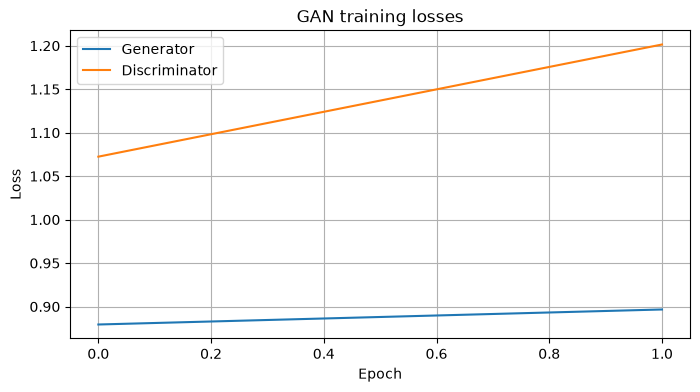

In [14]:
plt.figure(figsize=(8,4)); plt.plot(g_history,label="Generator"); plt.plot(d_history,label="Discriminator")
plt.xlabel("Epoch"); plt.ylabel("Loss"); plt.title("GAN training losses"); plt.legend(); plt.grid(True); plt.show()

## 7. Generate synthetic images

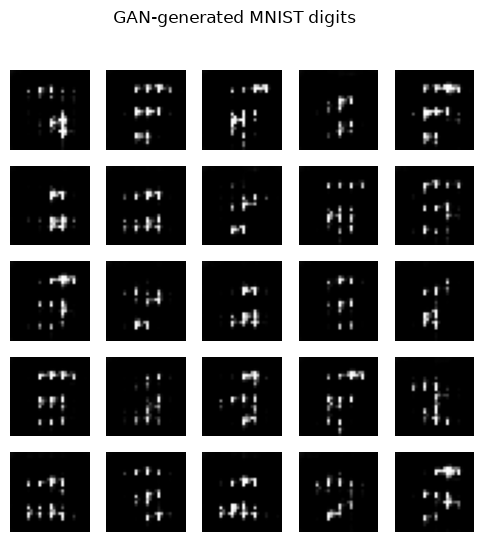

In [15]:
noise=tf.random.normal([25,LATENT_DIM])
samples=generator(noise,training=False)
fig,axes=plt.subplots(5,5,figsize=(6,6))
for ax,img in zip(axes.flat,samples):
    ax.imshow((img[:,:,0].numpy()+1)/2,cmap="gray"); ax.axis("off")
plt.suptitle("GAN-generated MNIST digits"); plt.show()

## 8. Compare real and generated images

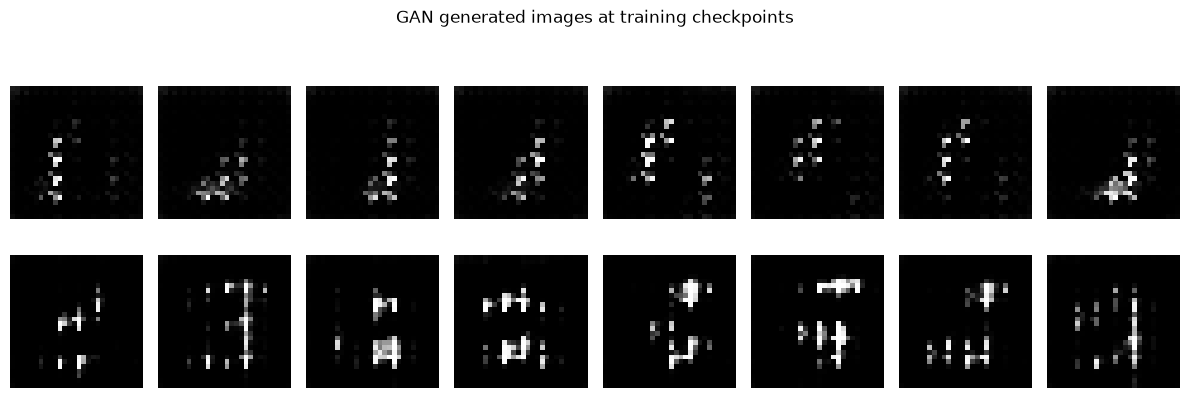

In [16]:
fig,axes=plt.subplots(EPOCHS,8,figsize=(12,2.2*EPOCHS), squeeze=False)
for epoch, epoch_samples in enumerate(checkpoint_samples):
    for i, img in enumerate(epoch_samples[:8]):
        axes[epoch,i].imshow((img[:,:,0]+1)/2,cmap="gray"); axes[epoch,i].axis("off")
    axes[epoch,0].set_ylabel(f"Epoch {epoch+1}")
plt.suptitle("GAN generated images at training checkpoints"); plt.tight_layout(); plt.show()


## 9. Conclusion
Discuss image sharpness, diversity, training stability, and possible mode collapse. GAN loss values alone do not prove image quality.